# Shifting every image without a loop

Exercise 22 builds `X_train_shifted` one image at a time: for each of the 60,000 images it finds the limits of the digit, draws two offsets within them, and moves the pixels. Can the same set be built without a loop over the images, and is it worth it? The code below starts from exercise 22's solution: solve 22 first.

Before reading on, you can try it yourself: time the two parts of the loop apart, finding the offsets and moving the pixels. Which one would vectorising speed up?

## The loop of exercise 22

MNIST, loaded as in the exercises:

In [ ]:
import hashlib
import urllib.request
from pathlib import Path

import numpy as np

MNIST_URL = "https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz"
MNIST_SHA256 = "731c5ac602752760c8e48fbffcf8c3b850d9dc2a2aedcf2cc48468fc17b673d1"

type ImagesAndLabels = tuple[np.ndarray, np.ndarray]


def load_mnist(cache_dir: Path = Path("data")) -> tuple[ImagesAndLabels, ImagesAndLabels]:
    """Download MNIST into `cache_dir` once, check it, and return its (train, test) splits."""
    cache_dir.mkdir(exist_ok=True)
    path = cache_dir / "mnist.npz"
    if not path.exists():
        urllib.request.urlretrieve(MNIST_URL, path)
    if hashlib.sha256(path.read_bytes()).hexdigest() != MNIST_SHA256:
        path.unlink()
        raise ValueError("The download is corrupted and has been deleted: run the cell again")
    with np.load(path) as mnist:
        return (mnist["x_train"], mnist["y_train"]), (mnist["x_test"], mnist["y_test"])


(X_train, y_train), _ = load_mnist()
X_train.shape

(60000, 28, 28)

`shift_image` moves the pixels of one image, filling with zeros what comes in from outside:

In [ ]:
def shift_image(image: np.ndarray, dx: int, dy: int) -> np.ndarray:
    height, width = image.shape
    shifted = np.zeros_like(image)
    destination_rows = slice(max(dy, 0), height + min(dy, 0))
    destination_cols = slice(max(dx, 0), width + min(dx, 0))
    source_rows = slice(max(-dy, 0), height + min(-dy, 0))
    source_cols = slice(max(-dx, 0), width + min(-dx, 0))
    shifted[destination_rows, destination_cols] = image[source_rows, source_cols]
    return shifted

`find_limits` gives the first and last rows and columns with ink:

In [ ]:
def find_limits(image: np.ndarray) -> tuple[int, int, int, int]:
    rows_with_ink = np.flatnonzero(image.any(axis=1))
    cols_with_ink = np.flatnonzero(image.any(axis=0))
    return int(rows_with_ink[0]), int(rows_with_ink[-1]), int(cols_with_ink[0]), int(cols_with_ink[-1])


find_limits(X_train[0])

(5, 24, 4, 23)

And `random_shift` draws one offset per axis within those limits, so that no ink is cut. Each of its 60,000 calls does both parts: finding the offsets (`find_limits` and two draws) and moving the pixels (`shift_image`).

In [ ]:
rng = np.random.default_rng(seed=0)


def random_shift(image: np.ndarray) -> np.ndarray:
    height, width = image.shape
    top, bottom, left, right = find_limits(image)
    dy = rng.integers(-top, height - bottom)
    dx = rng.integers(-left, width - right)
    return shift_image(image, dx=dx, dy=dy)


X_train_shifted = np.array([random_shift(image) for image in X_train])
X_train_shifted.shape

(60000, 28, 28)

## The offsets without a loop

`images.any(axis=2)` says, for every image and every row, whether the row has ink: a boolean array of shape (60000, 28). `argmax` on a boolean array returns the position of the first `True`, so it finds the first row with ink of every image at once, and on the reversed array the last one. Given arrays of limits, `rng.integers` draws one number per image. The offsets are drawn apart from the shift, so that the loop and the vectorised shift can later be given the same ones:

In [ ]:
def random_offsets_all(images: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    _, height, width = images.shape
    rows_with_ink = images.any(axis=2)
    cols_with_ink = images.any(axis=1)
    top = rows_with_ink.argmax(axis=1)
    bottom = height - 1 - rows_with_ink[:, ::-1].argmax(axis=1)
    left = cols_with_ink.argmax(axis=1)
    right = width - 1 - cols_with_ink[:, ::-1].argmax(axis=1)
    dy = rng.integers(-top, height - bottom)
    dx = rng.integers(-left, width - right)
    return dx, dy


dx, dy = random_offsets_all(X_train)
dx[:5], dy[:5]

(array([-4, -2, -2,  5, -2]), array([-3,  2, -1, -4,  1]))

## The shift without a loop

A slice takes the same window from every image, and here each image needs its own. That takes indexing with arrays of indices, one array per axis: NumPy's *advanced indexing*, often called fancy indexing.

Pixel `(r, c)` of a shifted image comes from pixel `(r - dy, c - dx)` of the original. Some of those indices fall outside the image: negative ones would silently wrap around to the other side, and too-large ones raise an `IndexError`. A border of zeros, as wide as the image on every side, moves all of them into range, and supplies the zeros: pixel `(r - dy, c - dx)` of the original is pixel `(28 + r - dy, 28 + c - dx)` of the padded image.

In [ ]:
def shift_all(images: np.ndarray, dx: np.ndarray, dy: np.ndarray) -> np.ndarray:
    count, height, width = images.shape
    padded = np.pad(images, ((0, 0), (height, height), (width, width)))  # (count, 3*height, 3*width)
    rows = height - dy[:, None] + np.arange(height)  # (count, height)
    cols = width - dx[:, None] + np.arange(width)  # (count, width)
    return padded[np.arange(count)[:, None, None], rows[:, :, None], cols[:, None, :]]


X_train_shifted_all = shift_all(X_train, dx, dy)
X_train_shifted_all.shape

(60000, 28, 28)

`rows[n, r]` is the row of the padded image that row `r` of image `n` reads, and `cols[n, c]` the column that column `c` reads. In the last line the three index arrays have shapes (60000, 1, 1), (60000, 28, 1) and (60000, 1, 28). NumPy broadcasts them to one shape, which is the shape of the result, and then output pixel `[n, r, c]` reads `padded[n, rows[n, r], cols[n, c]]`:

In [ ]:
np.broadcast_shapes((60_000, 1, 1), (60_000, 28, 1), (60_000, 1, 28))

(60000, 28, 28)

[Fancy indexing, step by step](https://github.com/avidaldo/ai/blob/main/pia/python-data-essentials/numpy/deep-dives/fancy_indexing_step_by_step.ipynb) explains indexing with arrays one rule at a time, and ends with this line on arrays small enough to print. The first image, before and after:

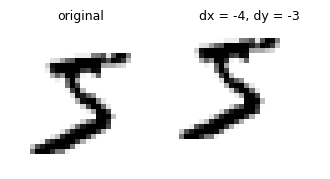

In [ ]:
import matplotlib.pyplot as plt

figure, axes = plt.subplots(1, 2, figsize=(4, 2.2))
titles = ["original", f"dx = {dx[0]}, dy = {dy[0]}"]
for ax, image, title in zip(axes, [X_train[0], X_train_shifted_all[0]], titles, strict=True):
    ax.imshow(image, cmap="binary")
    ax.set_title(title, fontsize=9)
    ax.axis("off")
plt.show()

## Checking both parts

The strongest check of a rewrite is to compare it with the simple version on the same input. With the same offsets, the loop and `shift_all` must give the same images, pixel for pixel:

In [ ]:
def shift_one_by_one(images: np.ndarray, dx: np.ndarray, dy: np.ndarray) -> np.ndarray:
    return np.array([shift_image(image, dx=x, dy=y) for image, x, y in zip(images, dx, dy, strict=True)])


np.array_equal(X_train_shifted_all, shift_one_by_one(X_train, dx, dy))

True

That checks the shift, not the offsets: with offsets out of range, both versions would cut the same ink and still agree. Exercise 22's check, that every image keeps its ink, covers the offsets. On its own it wouldn't be enough, since a function that returns its images unchanged keeps the ink too; together, the two checks cover both parts:

In [ ]:
np.array_equal(X_train_shifted_all.sum(axis=(1, 2)), X_train.sum(axis=(1, 2)))

True

## Where the time goes

A single measurement varies a lot when large arrays are allocated, so `timeit.repeat` runs each version five times, and the fastest run counts: the rest of the machine can only add time, never take it away. The seconds are this machine's; the proportions are what matters. First the shift alone, all with the same offsets: the two steps of `shift_all`, padding and gathering, against the loop. Their inputs are built first:

In [ ]:
import timeit
from collections.abc import Callable


def best_seconds(function: Callable[[], object]) -> float:
    return min(timeit.repeat(function, number=1, repeat=5))


padded = np.pad(X_train, ((0, 0), (28, 28), (28, 28)))
rows = 28 - dy[:, None] + np.arange(28)
cols = 28 - dx[:, None] + np.arange(28)
image_index = np.arange(len(X_train))[:, None, None]
padded.nbytes / 1e6, X_train.nbytes / 1e6

(423.36, 47.04)

The padded copy takes 423 MB, nine times `X_train`. Now padding, gathering and the loop, in seconds:

In [ ]:
pad_seconds = best_seconds(lambda: np.pad(X_train, ((0, 0), (28, 28), (28, 28))))
gather_seconds = best_seconds(lambda: padded[image_index, rows[:, :, None], cols[:, None, :]])
shift_loop_seconds = best_seconds(lambda: shift_one_by_one(X_train, dx, dy))
round(pad_seconds, 3), round(gather_seconds, 3), round(shift_loop_seconds, 3)

(0.086, 0.11, 0.113)

Each vectorised step costs about as much as the whole loop, so the vectorised shift is *slower*. The loop runs 60,000 times, and each time it copies a whole block of rows with one slice assignment, which NumPy does as a few fast copies of contiguous memory. The vectorised version first allocates and fills the padded copy, and then computes a separate address for each of the 47 million output pixels, reading three index arrays to do it.

Now the offsets: the limits and the draws one image at a time, as exercise 22 does them, against `random_offsets_all`:

In [ ]:
def random_offsets_one_by_one(images: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    dx, dy = [], []
    for image in images:
        height, width = image.shape
        top, bottom, left, right = find_limits(image)
        dy.append(rng.integers(-top, height - bottom))
        dx.append(rng.integers(-left, width - right))
    return np.array(dx), np.array(dy)


offsets_loop_seconds = best_seconds(lambda: random_offsets_one_by_one(X_train))
offsets_vectorised_seconds = best_seconds(lambda: random_offsets_all(X_train))
round(offsets_loop_seconds, 3), round(offsets_vectorised_seconds, 3), round(offsets_loop_seconds / offsets_vectorised_seconds, 1)

(0.281, 0.043, 6.5)

Here the loop loses by far. It calls `find_limits` 60,000 times and `rng.integers` 120,000 times, and each call does so little work that most of its time is the fixed cost of calling a function from Python. Vectorising pays off when that fixed cost is most of the work, as in the offsets; it doesn't when each iteration already hands a whole block to NumPy, as in the shift.

Last, the whole job, as exercise 22 does it, against the vectorised version and against a mix of the two, with the offsets vectorised and the shift in a loop. Each ratio is how many times faster than the loop:

In [ ]:
whole_loop_seconds = best_seconds(lambda: np.array([random_shift(image) for image in X_train]))
vectorised_seconds = best_seconds(lambda: shift_all(X_train, *random_offsets_all(X_train)))
mixed_seconds = best_seconds(lambda: shift_one_by_one(X_train, *random_offsets_all(X_train)))
round(whole_loop_seconds / vectorised_seconds, 1), round(whole_loop_seconds / mixed_seconds, 1)

(1.6, 2.4)

## Is it worth it?

The vectorised version is faster overall, and all of its gain comes from the offsets. A single total would have hidden that one part got faster and the other slower, so measure before you optimise, and measure the parts apart.

The mix is the fastest of the three, and keeps the readable `shift_image`. The full rewrite isn't worth it here. Its shift is slower exactly where it was meant to help, it needs a padded copy nine times the size of the data, and its fancy indexing hides the idea that `shift_image` states plainly. Vectorising pays off when it replaces many small calls, as for the offsets, or a loop over single elements, as in exercise 13; not when each iteration already hands a whole block to NumPy. In practice, libraries such as torchvision do augmentation for you.